# Global Retail Sales Analysis: Are We Growing Profitably?

**Business question.** The VP of Sales says: *"Sales have grown every year, but I am not sure we are growing profitably. Where do we make money, where do we lose it, and what should we change?"*

**Data.** 51,290 order lines (25,035 orders) from 2011 to 2014 for a global retailer: sales, profit, discount, shipping, product, customer and geography. This is the public "Global Superstore" sample dataset, so the figures are fictional.

**Tools.** Python, pandas, Matplotlib, Seaborn, Plotly Express.


## 1. Load and inspect the data

In [4]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", "{:,.2f}".format)
sns.set_theme(style="whitegrid")

os.makedirs("images", exist_ok=True)

URL = ("https://raw.githubusercontent.com/pplonski/datasets-for-start/"
       "refs/heads/master/superstore-sales/superstore_dataset2011-2015.csv")

In [5]:
# The file is not UTF-8, so it must be read with latin1 encoding
df = pd.read_csv(URL, encoding="latin1")
print(df.shape)
df.head()

(51290, 24)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,City,State,Country,Postal Code,Market,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit,Shipping Cost,Order Priority
0,42433,AG-2011-2040,1/1/2011,6/1/2011,Standard Class,TB-11280,Toby Braunhardt,Consumer,Constantine,Constantine,Algeria,NaN,Africa,Africa,OFF-TEN-10000025,Office Supplies,Storage,"Tenex Lockers, Blue",408.30,2,0.00,106.14,35.46,Medium
1,22253,IN-2011-47883,1/1/2011,8/1/2011,Standard Class,JH-15985,Joseph Holt,Consumer,Wagga Wagga,New South Wales,Australia,NaN,APAC,Oceania,OFF-SU-10000618,Office Supplies,Supplies,"Acme Trimmer, High Speed",120.37,3,0.10,36.04,9.72,Medium
2,48883,HU-2011-1220,1/1/2011,5/1/2011,Second Class,AT-735,Annie Thurman,Consumer,Budapest,Budapest,Hungary,NaN,EMEA,EMEA,OFF-TEN-10001585,Office Supplies,Storage,"Tenex Box, Single Width",66.12,4,0.00,29.64,8.17,High
3,11731,IT-2011-3647632,1/1/2011,5/1/2011,Second Class,EM-14140,Eugene Moren,Home Office,Stockholm,Stockholm,Sweden,NaN,EU,North,OFF-PA-10001492,Office Supplies,Paper,"Enermax Note Cards, Premium",44.87,3,0.50,-26.05,4.82,High
4,22255,IN-2011-47883,1/1/2011,8/1/2011,Standard Class,JH-15985,Joseph Holt,Consumer,Wagga Wagga,New South Wales,Australia,NaN,APAC,Oceania,FUR-FU-10003447,Furniture,Furnishings,"Eldon Light Bulb, Duo Pack",113.67,5,0.10,37.77,4.70,Medium


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 51290 entries, 0 to 51289
Data columns (total 24 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Row ID          51290 non-null  int64  
 1   Order ID        51290 non-null  object 
 2   Order Date      51290 non-null  object 
 3   Ship Date       51290 non-null  object 
 4   Ship Mode       51290 non-null  object 
 5   Customer ID     51290 non-null  object 
 6   Customer Name   51290 non-null  object 
 7   Segment         51290 non-null  object 
 8   City            51290 non-null  object 
 9   State           51290 non-null  object 
 10  Country         51290 non-null  object 
 11  Postal Code     9994 non-null   float64
 12  Market          51290 non-null  object 
 13  Region          51290 non-null  object 
 14  Product ID      51290 non-null  object 
 15  Category        51290 non-null  object 
 16  Sub-Category    51290 non-null  object 
 17  Product Name    51290 non-null 

In [7]:
missing = df.isna().sum()
print("Columns with missing values:")
print(missing[missing > 0])
print()
print("Fully duplicated rows:", df.duplicated().sum())
print("Unique orders:   ", df["Order ID"].nunique())
print("Unique customers:", df["Customer ID"].nunique())
print("Unique products: ", df["Product ID"].nunique())

Columns with missing values:
Postal Code    41296
dtype: int64

Fully duplicated rows: 0
Unique orders:    25035
Unique customers: 1590
Unique products:  10292


**What the inspection shows.** There are 51,290 rows and 24 columns. The only column with missing values is `Postal Code` (41,296 rows, 80.5%). There are no duplicate rows. There are 25,035 unique orders, so one order contains about two lines on average. Because of that, "count of rows" means *order lines* in this notebook, not orders.

## 2. Clean and prepare

In [8]:
# 2.1 Standardise column names to snake_case
df.columns = (df.columns.str.strip().str.lower()
              .str.replace("-", "_").str.replace(" ", "_"))

# 2.2 Convert date columns (the file mixes two date formats)
df["order_date"] = pd.to_datetime(df["order_date"], format="mixed", dayfirst=True)
df["ship_date"] = pd.to_datetime(df["ship_date"], format="mixed", dayfirst=True)

# 2.3 New columns
df["order_year"] = df["order_date"].dt.year
df["order_month"] = df["order_date"].dt.to_period("M").dt.to_timestamp()
df["ship_days"] = (df["ship_date"] - df["order_date"]).dt.days
df["profit_margin_pct"] = df["profit"] / df["sales"] * 100
df["discount_band"] = pd.cut(
    df["discount"],
    bins=[-0.01, 0, 0.1, 0.2, 0.4, 1.0],
    labels=["None", "1-10%", "11-20%", "21-40%", "Over 40%"],
)
df["high_discount"] = df["discount"] > 0.20

# 2.4 postal_code: kept as is (see cleaning log)
us_rows = df["country"] == "United States"
print("Missing postal codes:", df["postal_code"].isna().sum())
print("Missing postal codes in US rows:", df.loc[us_rows, "postal_code"].isna().sum())

Missing postal codes: 41296
Missing postal codes in US rows: 0


In [9]:
# Sanity checks: fail loudly if the cleaned data is not what we expect
assert df.shape[0] == 51290
assert df["order_date"].min() == pd.Timestamp("2011-01-01")
assert df["order_date"].max() == pd.Timestamp("2014-12-31")
assert (df["ship_days"] >= 0).all()
assert df["discount_band"].notna().all()
print("All sanity checks passed.")

All sanity checks passed.


**Cleaning log**

| Change | Why |
|---|---|
| Column names converted to `snake_case` | Easier to type and consistent (`Sub-Category` becomes `sub_category`). |
| File read with `encoding="latin1"` | The file is not UTF-8 and fails to load otherwise. |
| `order_date` and `ship_date` converted to datetimes using `format="mixed", dayfirst=True` | The columns mix two date styles; parsing them as dates is required for any time analysis. |
| Added `order_year`, `order_month` | Needed for yearly and monthly trends. |
| Added `ship_days` | Days from order to shipment, used to compare ship modes. |
| Added `profit_margin_pct` | Profit as a percentage of sales per line. |
| Added `discount_band` and `high_discount` (discount above 20%) | Discounts are continuous; bands make the profit effect readable. |
| `postal_code` left unchanged (80.5% missing) | Every missing value is outside the US, where postal codes were never recorded. No question in this analysis needs postal codes, so filling or dropping would add noise or lose rows. The column is simply not used. |
| No rows dropped | There are no duplicates and no missing values in any column used. |

## 3. Summary tables

In [10]:
# Headline numbers
total_sales = df["sales"].sum()
total_profit = df["profit"].sum()
margin_pct = total_profit / total_sales * 100
n_orders = df["order_id"].nunique()
print(f"Total sales:  ${total_sales:,.0f}")
print(f"Total profit: ${total_profit:,.0f}")
print(f"Margin:       {margin_pct:.2f}%")
print(f"Orders:       {n_orders:,}")

# Yearly summary
yearly = df.groupby("order_year").agg(sales=("sales", "sum"), profit=("profit", "sum")).reset_index()
yearly["margin_pct"] = yearly["profit"] / yearly["sales"] * 100

# Category summary (highest profit first)
category_summary = df.groupby("category").agg(sales=("sales", "sum"), profit=("profit", "sum")).reset_index()
category_summary["margin_pct"] = category_summary["profit"] / category_summary["sales"] * 100
category_summary = category_summary.sort_values("profit", ascending=False)

# Market summary (highest sales first)
market_summary = df.groupby("market").agg(sales=("sales", "sum"), profit=("profit", "sum")).reset_index()
market_summary["margin_pct"] = market_summary["profit"] / market_summary["sales"] * 100
market_summary = market_summary.sort_values("sales", ascending=False)

# Region summary (lowest margin first)
region_summary = df.groupby("region").agg(sales=("sales", "sum"), profit=("profit", "sum")).reset_index()
region_summary["margin_pct"] = region_summary["profit"] / region_summary["sales"] * 100
region_summary = region_summary.sort_values("margin_pct")

# Sub-category summary (lowest profit first)
subcat_profit = df.groupby("sub_category").agg(sales=("sales", "sum"), profit=("profit", "sum")).reset_index()
subcat_profit["margin_pct"] = subcat_profit["profit"] / subcat_profit["sales"] * 100
subcat_profit = subcat_profit.sort_values("profit")

discount_summary = (df.groupby("discount_band", observed=True)["profit"]
                      .agg(avg_profit_per_line="mean", order_lines="count")
                      .reset_index())

pt = df.pivot_table(index="market", columns="category", values="profit", aggfunc="sum")

monthly = (df.groupby("order_month")
             .agg(sales=("sales", "sum"), profit=("profit", "sum"))
             .reset_index())
monthly["mom_pct"] = monthly["sales"].pct_change() * 100
monthly["rolling_3m"] = monthly["sales"].rolling(3).mean()
monthly["order_year"] = monthly["order_month"].dt.year
monthly["month_num"] = monthly["order_month"].dt.month
monthly["sales_k"] = monthly["sales"] / 1000   # sales in $K, for charts

yearly

Total sales:  $12,642,502
Total profit: $1,467,457
Margin:       11.61%
Orders:       25,035


,order_year,sales,profit,margin_pct
0,2011,"2,259,450.90","248,940.81",11.02
1,2012,"2,677,438.69","307,415.28",11.48
2,2013,"3,405,746.45","406,935.23",11.95
3,2014,"4,299,865.87","504,165.97",11.73


In [11]:
category_summary

,category,sales,profit,margin_pct
2,Technology,"4,744,557.50","663,778.73",13.99
1,Office Supplies,"3,787,070.23","518,473.83",13.69
0,Furniture,"4,110,874.19","285,204.72",6.94


In [12]:
market_summary

,market,sales,profit,margin_pct
0,APAC,"3,585,744.13","436,000.05",12.16
4,EU,"2,938,089.06","372,829.74",12.69
6,US,"2,297,200.86","286,397.02",12.47
5,LATAM,"2,164,605.17","221,643.49",10.24
3,EMEA,"806,161.31","43,897.97",5.45
1,Africa,"783,773.21","88,871.63",11.34
2,Canada,"66,928.17","17,817.39",26.62


## 4. Are we growing profitably?

Text(0, 0.5, 'USD')

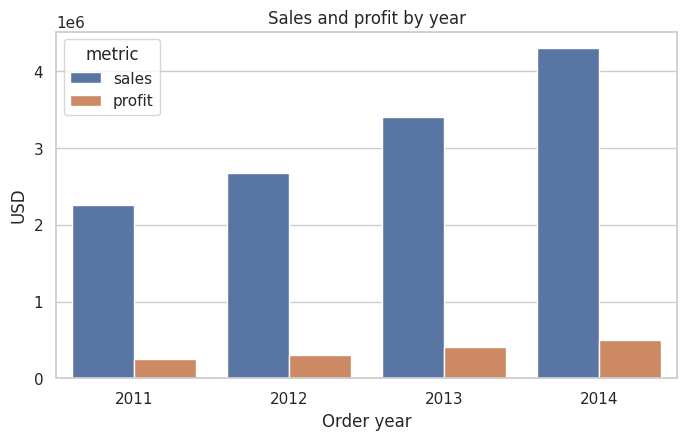

In [18]:
yearly_long = yearly.melt(id_vars="order_year", value_vars=["sales", "profit"],
                          var_name="metric", value_name="usd")

fig, ax = plt.subplots(figsize=(8, 4.5))
sns.barplot(data=yearly_long, x="order_year", y="usd", hue="metric", ax=ax)
ax.set_title("Sales and profit by year")
ax.set_xlabel("Order year")
ax.set_ylabel("USD")






## 5. Where do we make and lose money?

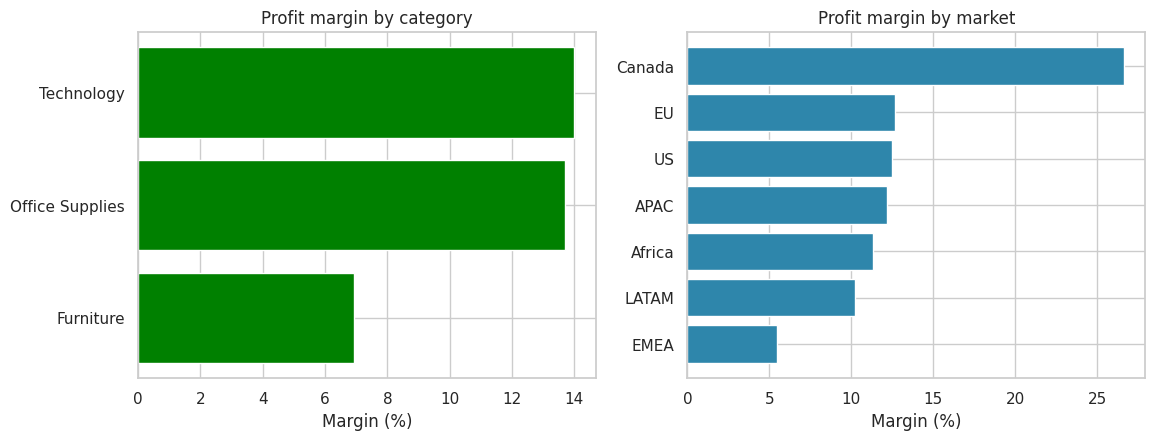

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Left: margin by category
cat = category_summary.sort_values("margin_pct")
axes[0].barh(cat["category"], cat["margin_pct"], color="green")

axes[0].set_title("Profit margin by category")
axes[0].set_xlabel("Margin (%)")


# Right: margin by market
mk = market_summary.sort_values("margin_pct")
axes[1].barh(mk["market"], mk["margin_pct"], color="#2e86ab")


axes[1].set_title("Profit margin by market")
axes[1].set_xlabel("Margin (%)")



plt.show()

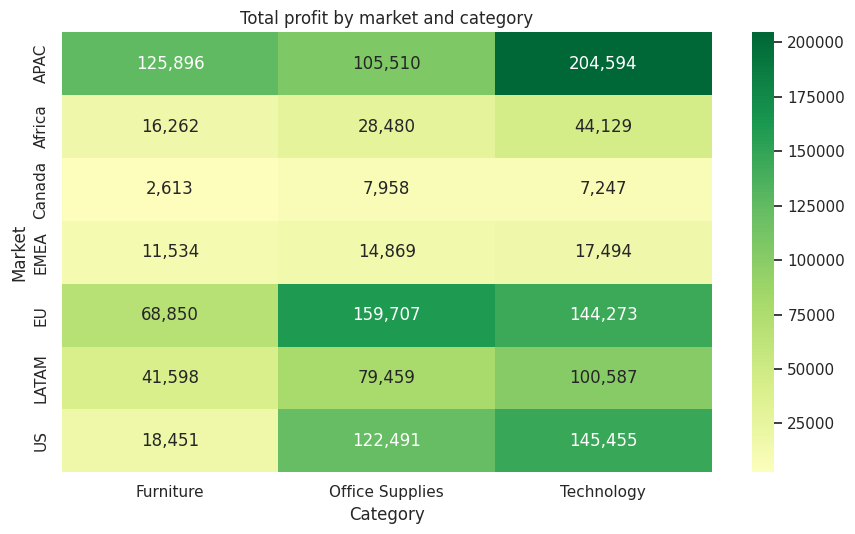

In [29]:
plt.figure(figsize=(9, 5.5))
sns.heatmap(pt, annot=True, fmt=",.0f", cmap="RdYlGn", center=0)
plt.title("Total profit by market and category")
plt.xlabel("Category")
plt.ylabel("Market")
plt.tight_layout()

plt.show()

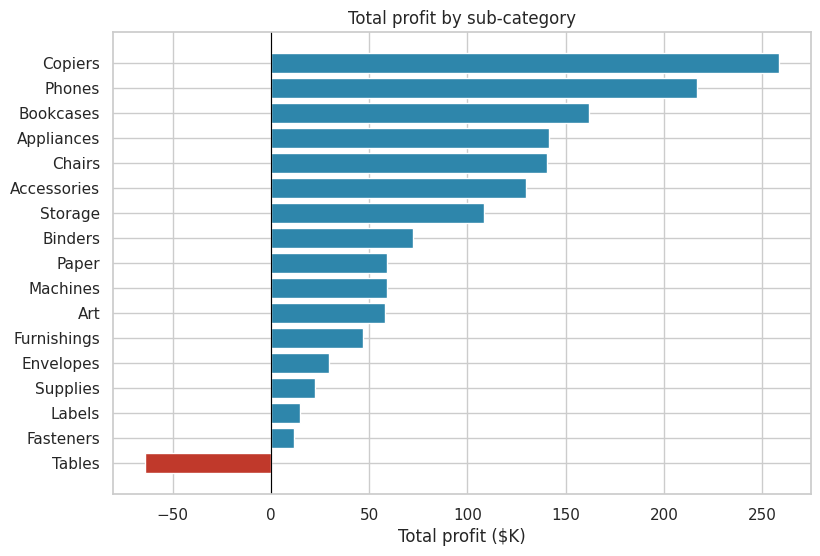

In [31]:
subcat_profit["profit_k"] = subcat_profit["profit"] / 1000   # in $K
colors = np.where(subcat_profit["profit"] < 0, "#c0392b", "#2e86ab")

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(subcat_profit["sub_category"], subcat_profit["profit_k"], color=colors)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("Total profit by sub-category")
ax.set_xlabel("Total profit ($K)")
ax.set_ylabel("")


plt.show()

**Insight.** Tables is the only sub-category that loses money overall (-$64K on $757K of sales, a margin of -8.5%). The best earners are Copiers ($259K), Phones ($217K) and Bookcases ($162K).

## 6. What is driving the losses? Discounts

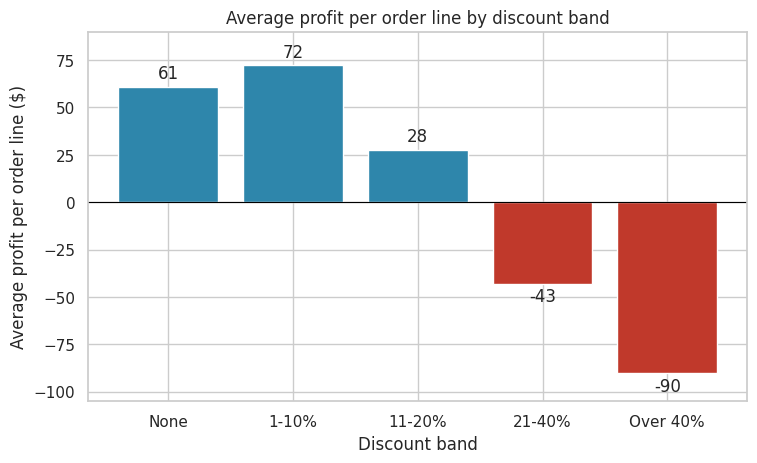

,discount_band,avg_profit_per_line,order_lines
0,None,61.04,29009
1,1-10%,72.28,4679
2,11-20%,27.61,6274
3,21-40%,-42.88,4367
4,Over 40%,-90.13,6961


In [33]:
colors = np.where(discount_summary["avg_profit_per_line"] < 0, "#c0392b", "#2e86ab")

fig, ax = plt.subplots(figsize=(8.5, 4.8))
ax.bar(discount_summary["discount_band"].astype(str), discount_summary["avg_profit_per_line"], color=colors)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_ylim(-105, 90)
ax.bar_label(ax.containers[0], fmt="%.0f", padding=3)
ax.set_title("Average profit per order line by discount band")
ax.set_xlabel("Discount band")
ax.set_ylabel("Average profit per order line ($)")

plt.show()
discount_summary

In [46]:
# How much does the high-discount group cost, and who uses it most?


#  Compare markets
market_check = df.groupby("market")[["sales", "profit", "shipping_cost"]].sum()
market_check["margin_pct"] = market_check["profit"] / market_check["sales"] * 100
market_check["shipping_pct_of_sales"] = market_check["shipping_cost"] / market_check["sales"] * 100


market_check = market_check[["margin_pct", "shipping_pct_of_sales"]].sort_values("margin_pct")
print(market_check)
print()


# Which sub-categories get the biggest discounts?
avg_discount = df.groupby("sub_category")["discount"].mean()
print()
print(avg_discount.sort_values(ascending=False).head(3))



# Lowest-margin regions
print()
print("Lowest-margin regions:")
print(region_summary.head(3))

        margin_pct  shipping_pct_of_sales
market                                   
EMEA          5.45                  10.96
LATAM        10.24                  10.82
Africa       11.34                  11.25
APAC         12.16                  10.80
US           12.47                  10.37
EU           12.69                  10.53
Canada       26.62                  11.07


sub_category
Tables     0.29
Binders    0.18
Machines   0.17
Name: discount, dtype: float64

Lowest-margin regions:
            region        sales     profit  margin_pct
11  Southeast Asia   884,423.17  17,852.33        2.02
5             EMEA   806,161.31  43,897.97        5.45
10           South 1,600,907.04 140,355.77        8.77


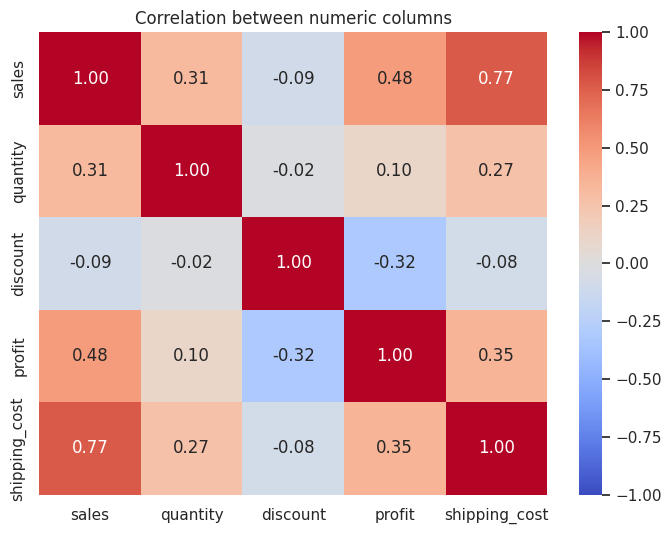

In [47]:
corr_cols = ["sales", "quantity", "discount", "profit", "shipping_cost"]
plt.figure(figsize=(7, 5.5))
sns.heatmap(df[corr_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm",
            center=0, vmin=-1, vmax=1)
plt.title("Correlation between numeric columns")
plt.tight_layout()
plt.savefig("images/06_correlation_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

**Insight.** Discount is the only variable negatively related to profit (-0.32). Sales (0.48) and shipping cost (0.35) are positively related to profit, partly because bigger orders have larger values for both.

## 7. Seasonality and market trends

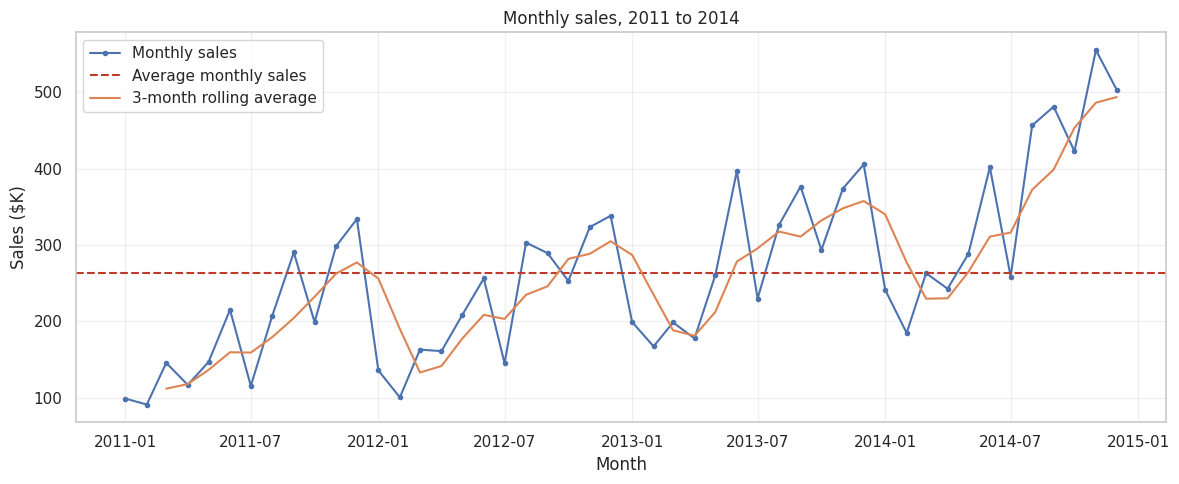

In [54]:
# Calculate the missing 3-month rolling average in thousands ($K)
monthly["rolling_3m_k"] = monthly["rolling_3m"] / 1000

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(monthly["order_month"], monthly["sales_k"], marker="o", markersize=3, label="Monthly sales")
ax.axhline(monthly["sales_k"].mean(), linestyle="--", color="#c0392b",
           label="Average monthly sales")
ax.plot(monthly["order_month"], monthly["rolling_3m_k"], label="3-month rolling average")
ax.set_title("Monthly sales, 2011 to 2014")
ax.set_xlabel("Month")
ax.set_ylabel("Sales ($K)")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

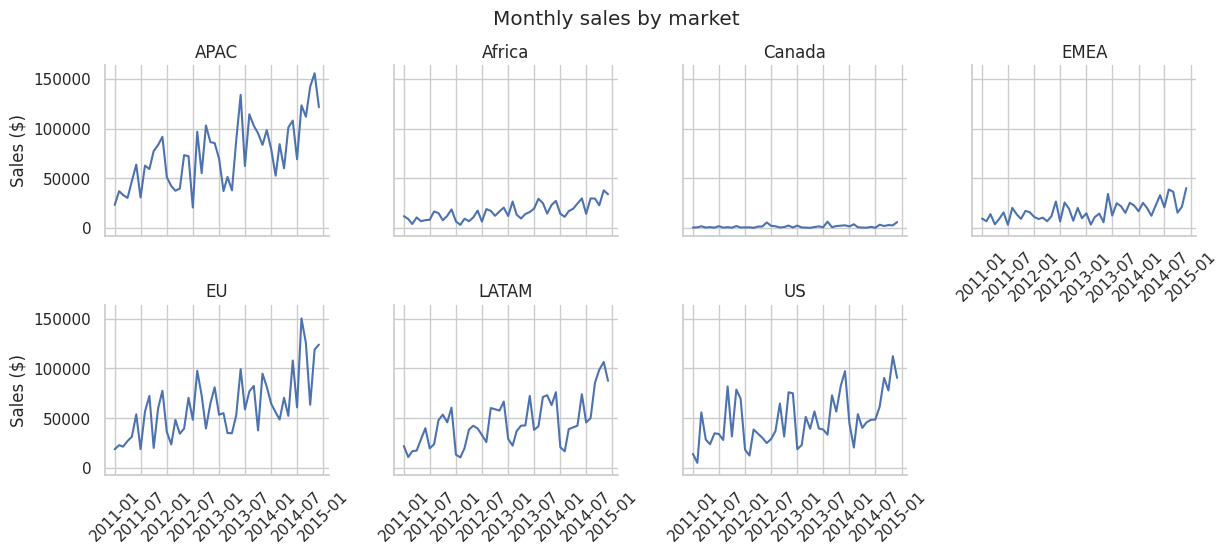

In [50]:
monthly_market = (df.groupby(["order_month", "market"])
                    .agg(sales=("sales", "sum")).reset_index())
g = sns.relplot(data=monthly_market, x="order_month", y="sales", col="market",
                col_wrap=4, kind="line", height=2.6, aspect=1.2)
g.set_titles("{col_name}")
g.set_axis_labels("", "Sales ($)")
g.tick_params(axis="x", rotation=45)
g.figure.suptitle("Monthly sales by market", y=1.03)
g.savefig("images/09_monthly_sales_by_market.png", dpi=150, bbox_inches="tight")
plt.show()

**Insight.** Every market is growing. APAC is the largest (28% of sales), followed by the EU (23%), US (18%) and LATAM (17%); Africa and EMEA are 6% each and Canada is about 0.5%. EMEA is therefore a small market where the margin problem is large in percentage terms but small in dollars ($44K of profit).

## 8. Interactive charts (Plotly)

These two charts are interactive: hover over points for details and click legend entries to hide a series. GitHub does not display Plotly interactivity inside notebooks, so open this notebook in Google Colab or nbviewer to use them.

In [51]:
fig = px.line(monthly, x="month_num", y="sales",
              color=monthly["order_year"].astype(str), markers=True,
              labels={"month_num": "Month", "sales": "Sales ($)", "color": "Year"},
              title="Seasonality: monthly sales by year (interactive)")
fig.update_xaxes(dtick=1)
fig.show()

In [52]:
fig = px.scatter(df.sample(5000, random_state=42), x="sales", y="profit",
                 color="category", opacity=0.6,
                 hover_data=["customer_name", "product_name", "discount"],
                 title="Sales vs profit, 5,000-line random sample (interactive)")
fig.show()